In [37]:
import CPanalysistools
from CPanalysistools import *

# 1. Load simulation workflows/result files

In [2]:
pheno_file = './phenopowerlaw/phenopowerlaw_128_rolled_copper_200_grains_5k_time_steps_2026-08-28_104710/execute/t_1/geom_load.hdf5'
pheno_wk = './phenopowerlaw/phenopowerlaw_128_rolled_copper_200_grains_5k_time_steps_2026-08-28_104710'
dislo_file = './dislo_density/dislotwin_128_rolled_copper_200_grains_5k_time_steps_2026-08-28_104634/execute/t_1/geom_load.hdf5'
dislo_wk = './dislo_density/dislotwin_128_rolled_copper_200_grains_5k_time_steps_2026-08-28_104634'

# 2. Extract/load relevant values and produce plots

### Stress triaxiality

In [3]:
pheno_triax = CPanalysistools.extractDAMASKdata.extract_stress_triaxiality(pheno_file, [128,128,128])

In [4]:
dislo_triax = CPanalysistools.extractDAMASKdata.extract_stress_triaxiality(dislo_file, [128,128,128])

In [5]:
pheno_triax = np.array(pheno_triax)
dislo_triax = np.array(dislo_triax)

In [ ]:
np.save("pheno_triax_200_grains.npy", pheno_triax)
np.save("dislo_triax_200_grains.npy", dislo_triax)

In [38]:
pheno_triax = np.load("../data/stress_triaxiality/pheno_triax_200_grains.npy")
dislo_triax = np.load("../data/stress_triaxiality/dislo_triax_200_grains.npy")

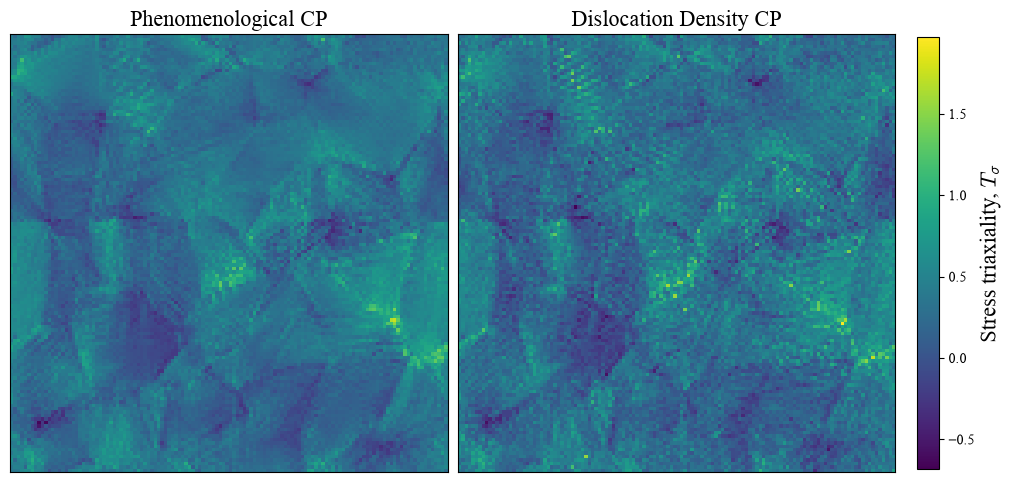

In [36]:
%matplotlib inline
fig_triax = CPanalysistools.comparison_map(np.flip(pheno_triax[:,:,0].transpose(), axis=0), 
                               np.flip(dislo_triax[:,:,0].transpose(), axis=0),
                               data1_label = 'Phenomenological CP',
                               data2_label = 'Dislocation Density CP',
                               color_bar_label = r'Stress triaxiality, $T_{\sigma}$',
                               savefig = True,
                               fig_name = "../figures/surface_stress_triaxiality_comparison_200_grains_128_VE.png"
                               )

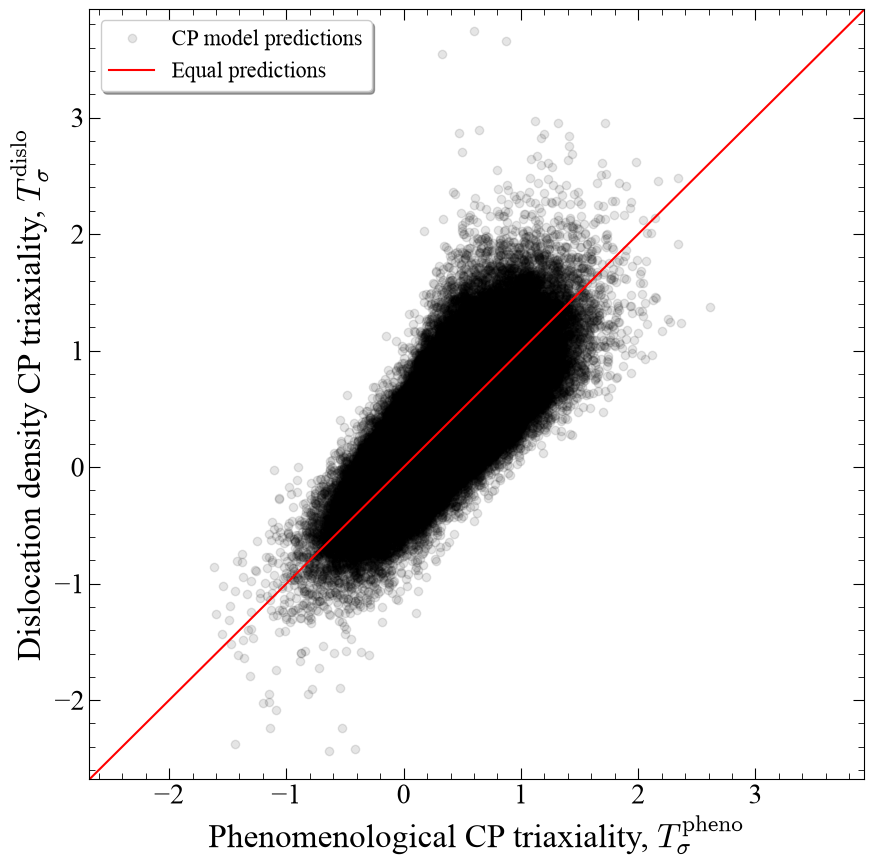

In [37]:
CPanalysistools.comparison_plot(pheno_triax.flatten(order = 'F'), dislo_triax.flatten(order = 'F'), 
                                r"Phenomenological CP triaxiality, $T_{\sigma}^{\text{pheno}}$",
                                r"Dislocation density CP triaxiality, $T_{\sigma}^{\text{dislo}}$",
                                savefig = True,
                                fig_name = "../figures/stress_triaxiality_comparison_200_grains_128_VE.png")

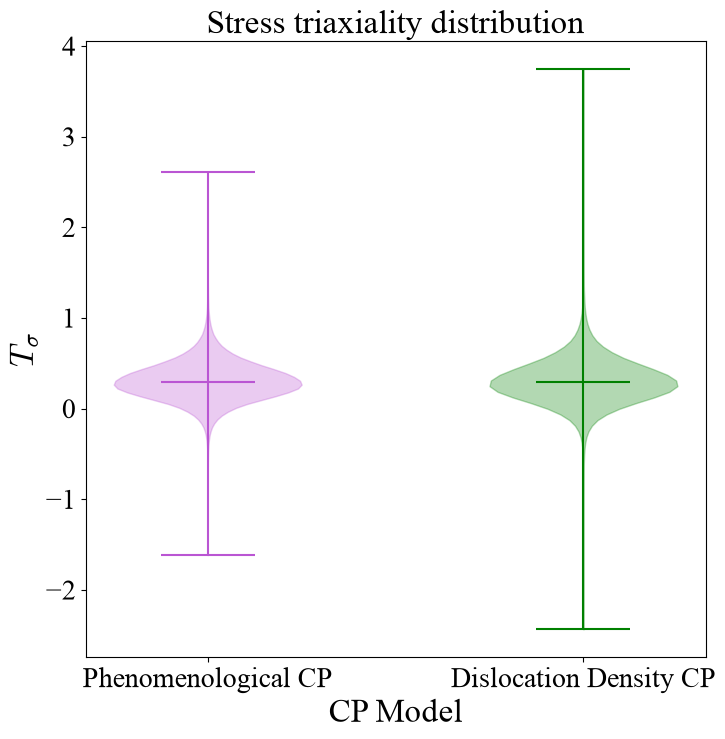

In [38]:
CPanalysistools.comparison_violin_plot(pheno_triax.flatten(order = 'F'), dislo_triax.flatten(order = 'F'), 
                       "Phenomenological CP", 
                       "Dislocation Density CP", 
                       "Stress triaxiality distribution", 
                       r"$T_{\sigma}$",
                       savefig = True,
                       fig_name = "../figures/stress_triaxiality_violin_plot_200_grains_128_VE.png")

Statistical comparison

In [8]:
CPanalysistools.statistical_comparison_metrics(pheno_triax, dislo_triax)

NRMSE (val 1 normalised): 0.504 
NRMSE (val 2 normalised): 0.496 
SSIM: 0.721 
Correlation coefficient: 0.772


### Strain component parallel to loading direction, $\varepsilon_{xx}$

In [39]:
pheno_xx_strain = np.load("../data/strain/pheno_128_xx_strain_200_grains.npy")
dislo_xx_strain = np.load("../data/strain/dislo_128_xx_strain_200_grains.npy") 

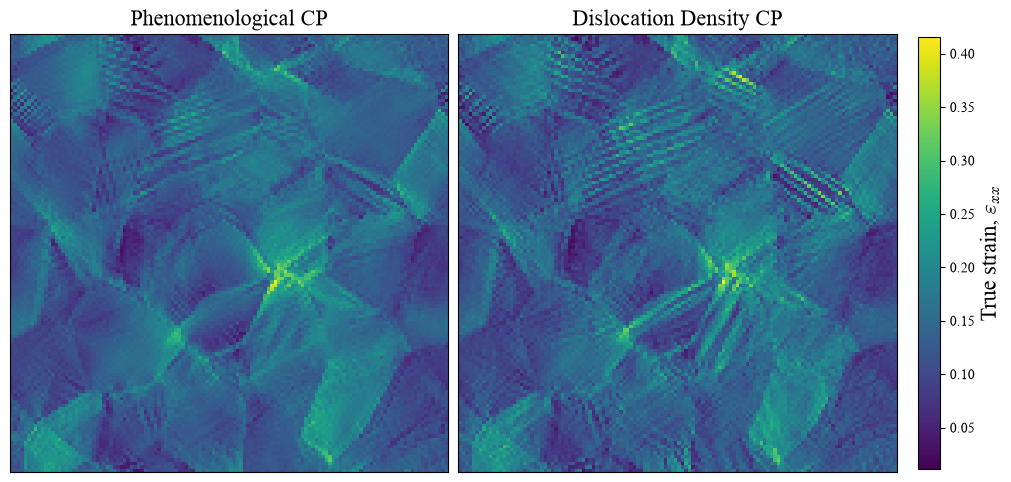

In [41]:
CPanalysistools.comparison_map(np.flip(pheno_xx_strain[:,:,0].transpose(), axis=0), 
                               np.flip(dislo_xx_strain[:,:,0].transpose(), axis=0),
                               data1_label = 'Phenomenological CP',
                               data2_label = 'Dislocation Density CP',
                               color_bar_label = r'True strain, $\varepsilon_{xx}$',
                               savefig = True,
                               fig_name = "surface_xx_strain_comparison_200_grains_128_VE.png")

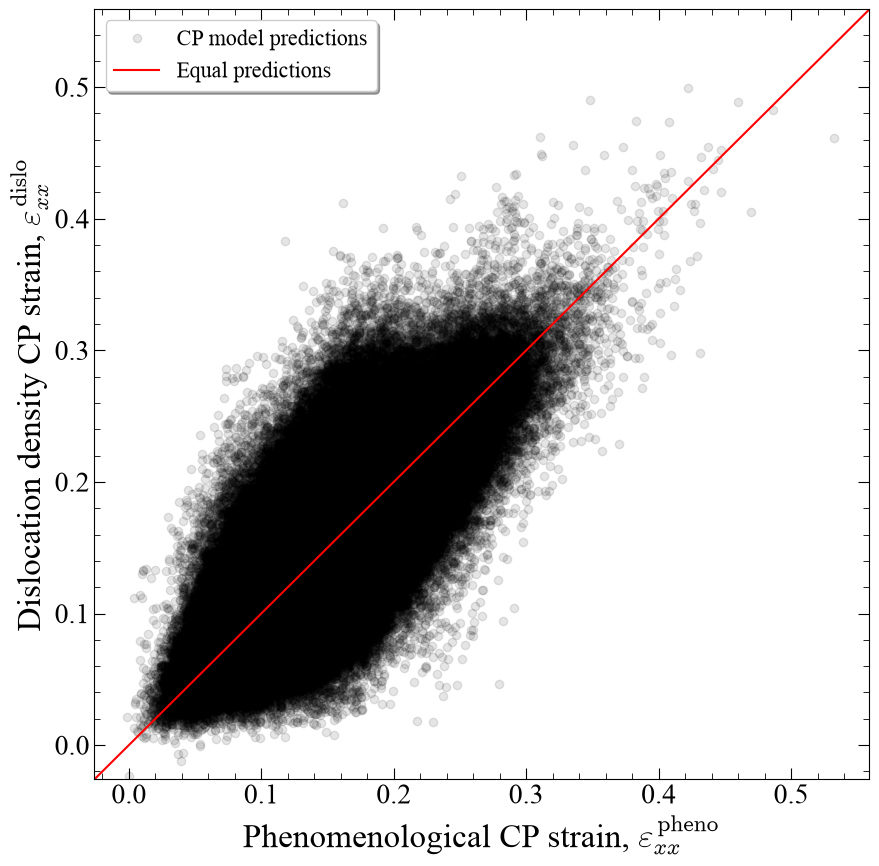

In [42]:
CPanalysistools.comparison_plot(pheno_xx_strain.flatten(order = 'F'), dislo_xx_strain.flatten(order = 'F'), 
                                r"Phenomenological CP strain, $\varepsilon_{xx}^{\text{pheno}}$",
                                r"Dislocation density CP strain, $\varepsilon_{xx}^{\text{dislo}}$",
                                savefig = True,
                                fig_name = "../figures/xx_strain_comparison_200_grains_128_VE.png")

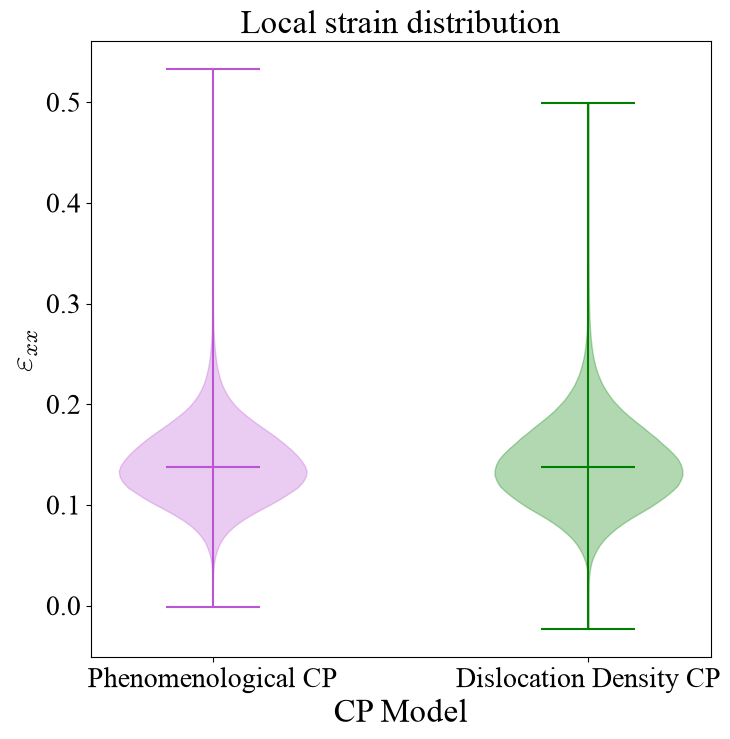

In [ ]:
CPanalysistools.comparison_violin_plot(pheno_xx_strain.flatten(order = 'F'), dislo_xx_strain.flatten(order = 'F'), 
                       "Phenomenological CP", 
                       "Dislocation Density CP", 
                       "Local strain distribution", 
                       r"$\varepsilon_{xx}$",
                       savefig = True,
                       fig_name = "../figures/xx_strain_violin_plot_200_grains_128_VE.png")

Statistical comparison

In [14]:
CPanalysistools.statistical_comparison_metrics(pheno_xx_strain, dislo_xx_strain)

NRMSE (val 1 normalised): 0.174 
NRMSE (val 2 normalised): 0.174 
SSIM: 0.698 
Correlation coefficient: 0.814


### Equivalent von Mises strain

In [40]:
pheno_vM_strain = np.load("../data/vM_strains/pheno_vM_strain_200_grains.npy")
dislo_vM_strain = np.load("../data/vM_strains/dislo_vM_strain_200_grains.npy") 

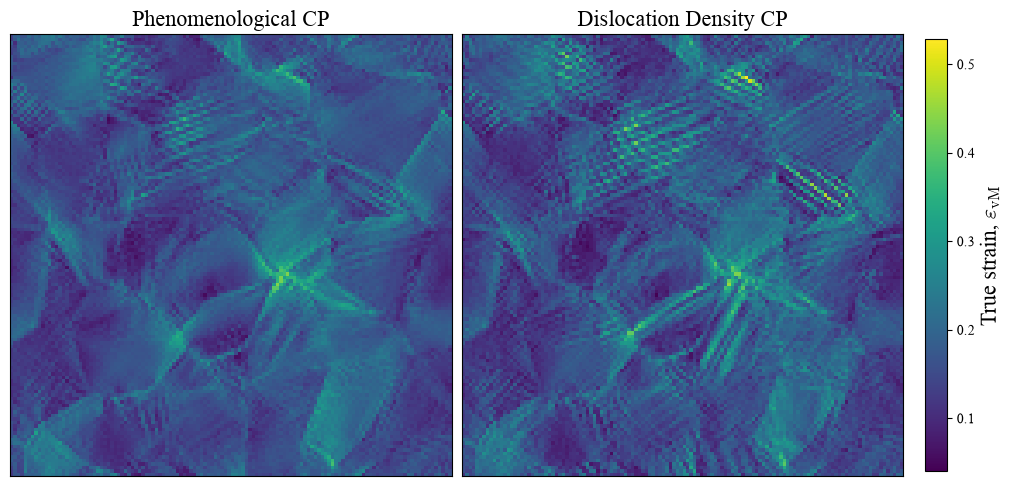

In [46]:
CPanalysistools.comparison_map(np.flip(pheno_vM_strain[:,:,0].transpose(), axis=0), 
                               np.flip(dislo_vM_strain[:,:,0].transpose(), axis=0),
                               data1_label = 'Phenomenological CP',
                               data2_label = 'Dislocation Density CP',
                               color_bar_label = r'True strain, $\varepsilon_{\text{vM}}$',
                               savefig = True,
                               fig_name = "../figures/surface_vM_equiv_strain_comparison_200_grains_128_VE.png")

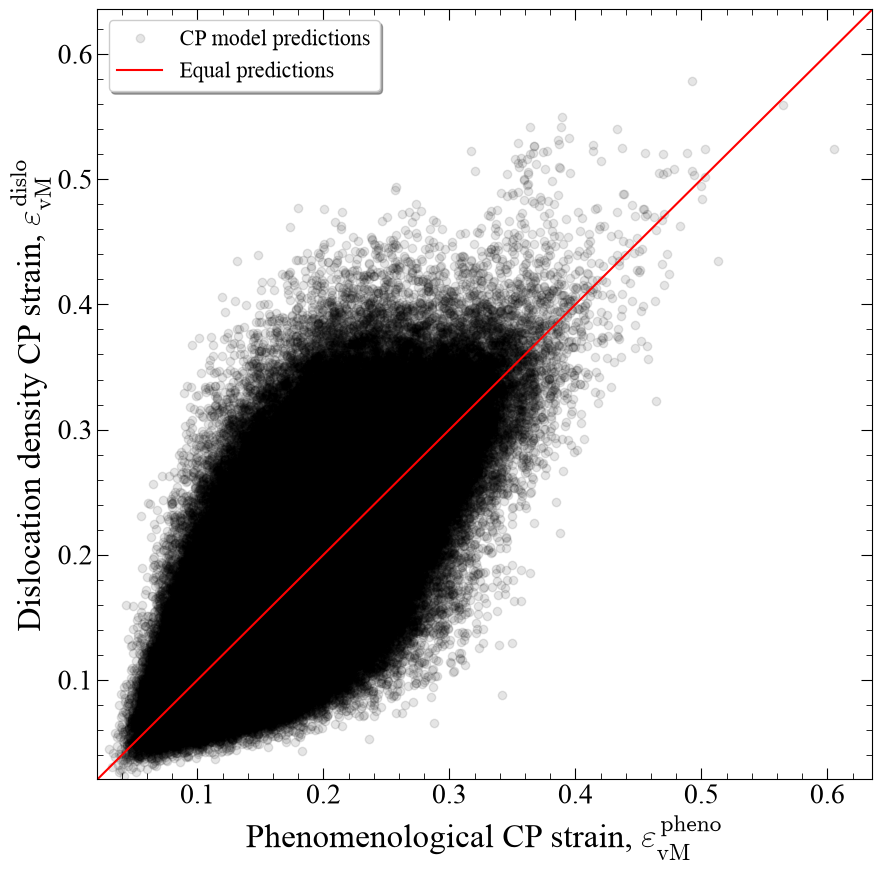

In [47]:
CPanalysistools.comparison_plot(pheno_vM_strain.flatten(order = 'F'), dislo_vM_strain.flatten(order = 'F'), 
                                r"Phenomenological CP strain, $\varepsilon_{\text{vM}}^{\text{pheno}}$",
                                r"Dislocation density CP strain, $\varepsilon_{\text{vM}}^{\text{dislo}}$",
                                savefig = True,
                                fig_name = "../figures/equiv_vM_strain_comparison_200_grains_128_VE.png")

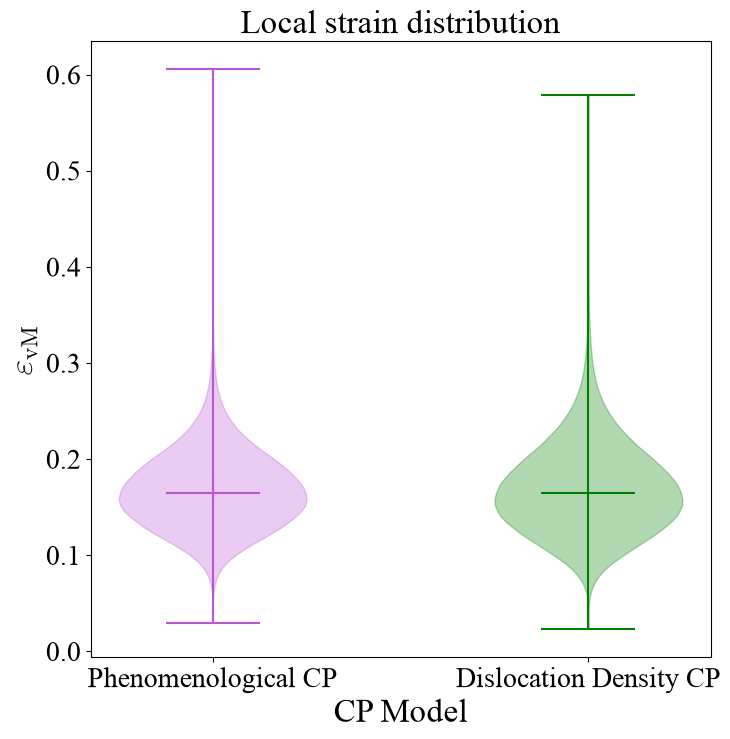

In [48]:
CPanalysistools.comparison_violin_plot(pheno_vM_strain.flatten(order = 'F'), dislo_vM_strain.flatten(order = 'F'), 
                       "Phenomenological CP", 
                       "Dislocation Density CP", 
                       "Local strain distribution", 
                       r"$\varepsilon_{\text{vM}}$",
                       savefig = True,
                       fig_name = "../figures/equiv_vM_strain_violin_plot_200_grains_128_VE.png")

Statistical comparison

In [49]:
CPanalysistools.statistical_comparison_metrics(pheno_vM_strain, dislo_vM_strain)

NRMSE (val 1 normalised): 0.184 
NRMSE (val 2 normalised): 0.183 
SSIM: 0.657 
Correlation coefficient: 0.769


### $r$-value and volume-averaged equivalent von Mises strains

In [41]:
pheno_r_vals = np.load("../data/r_value/pheno_r_vals_20_time_steps.npy")
dislo_r_vals = np.load("../data/r_value/dislo_r_vals_20_time_steps.npy")

In [42]:
pheno_equiv_vM_strain = np.load("../data/vM_strains/pheno_vM_strains_avg_20_time_steps.npy")
dislo_equiv_vM_strain = np.load("../data/vM_strains/dislo_vM_strains_avg_20_time_steps.npy")

(0.85, 0.86)

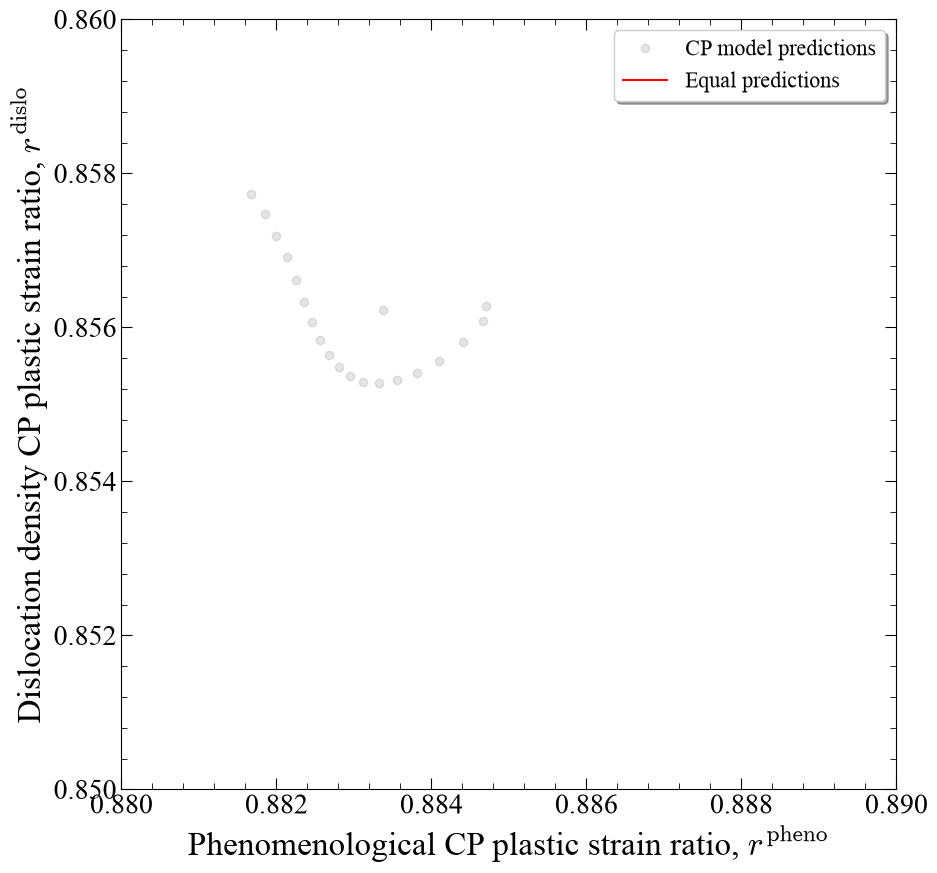

In [18]:
CPanalysistools.comparison_plot(pheno_r_vals[1:], 
                                dislo_r_vals[1:],
                                r"Phenomenological CP plastic strain ratio, $r^{\text{pheno}}$",
                                r"Dislocation density CP plastic strain ratio, $r^{\text{dislo}}$")
#plt.xlim(min(min(pheno_r_vals[1:]), min(dislo_r_vals[1:])), max(max(pheno_r_vals[1:]), max(dislo_r_vals[1:])))
plt.xlim(0.88, 0.89)
plt.ylim(0.85, 0.86)
#plt.ylim(min(min(pheno_r_vals[1:]), min(dislo_r_vals[1:])), max(max(pheno_r_vals[1:]), max(dislo_r_vals[1:])))

(0.0, 1.0)

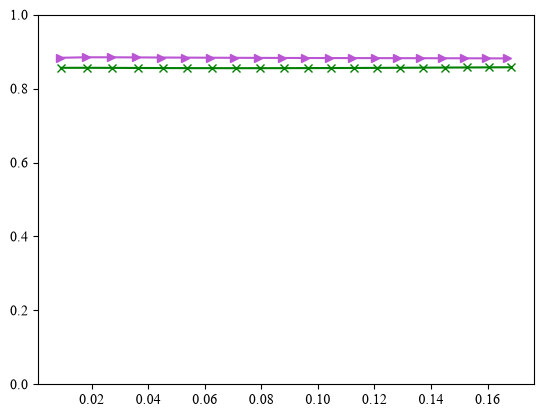

In [19]:
plt.plot(pheno_equiv_vM_strain[1:], pheno_r_vals[1:],  color = 'mediumorchid', marker = ">")
plt.plot(dislo_equiv_vM_strain[1:], dislo_r_vals[1:], color = 'green', marker = "x")
plt.ylim(0,1)

### Accumulated plastic strain energy density

In [20]:
pheno_mat_file = "./phenopowerlaw/phenopowerlaw_128_rolled_copper_200_grains_5k_time_steps_2026-08-28_104710/execute/t_1/material.yaml"
dislo_mat_file = "./dislo_density/dislotwin_128_rolled_copper_200_grains_5k_time_steps_2026-08-28_104634/execute/t_1/material.yaml"

In [4]:
%%time
extract_data = CPanalysistools.extractDAMASKdata()
pheno_psed_arrs, pheno_apsed = extract_data.extract_accum_plastic_strain_energy_density(damask_file = pheno_file, 
                                                                       mat_file = pheno_mat_file, 
                                                                       rve_shape = [128,128,128])

100%|██████████| 101/101 [04:58<00:00,  2.96s/it]


CPU times: user 3min 14s, sys: 1min 35s, total: 4min 49s
Wall time: 5min 7s


In [5]:
np.save("pheno_128_psed_per_inc_200_grains.npy", pheno_psed_arrs)
np.save("pheno_128_apsed_200_grains.npy", pheno_apsed)

In [10]:
pheno_psed_arrs.shape, pheno_apsed.shape

((101, 128, 128, 128), (128, 128, 128))

In [11]:
dislo_psed_arrs, dislo_apsed = extract_data.extract_accum_plastic_strain_energy_density(damask_file = dislo_file, 
                                                                       mat_file = dislo_mat_file, 
                                                                       rve_shape = [128,128,128])

100%|██████████| 101/101 [06:17<00:00,  3.74s/it]


In [12]:
np.save("dislo_128_psed_per_inc_200_grains.npy", dislo_psed_arrs)
np.save("dislo_128_apsed_200_grains.npy", dislo_apsed)

In [43]:
#pheno_psed_arrs = np.load("pheno_128_psed_per_inc_200_grains.npy")
pheno_apsed = np.load("../data/accumulated_plastic_work/pheno_128_apsed_200_grains.npy")
#dislo_psed_arrs = np.load("dislo_128_psed_per_inc_200_grains.npy")
dislo_apsed = np.load("../data/accumulated_plastic_work/dislo_128_apsed_200_grains.npy")

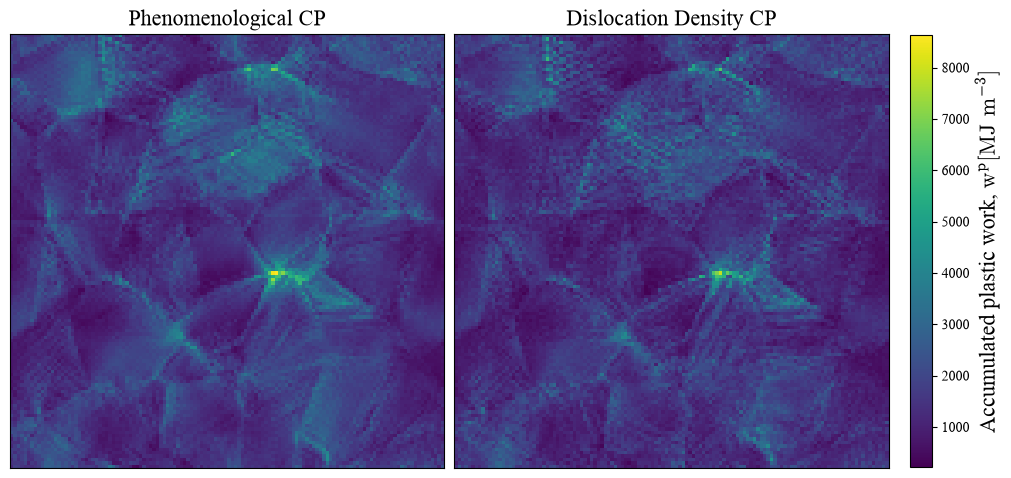

In [ ]:
%matplotlib inline
CPanalysistools.comparison_map(np.flip(pheno_apsed[:,:,0].transpose(), axis=0)*1e-6, 
                               np.flip(dislo_apsed[:,:,0].transpose(), axis=0)*1e-6,
                               data1_label = 'Phenomenological CP',
                               data2_label = 'Dislocation Density CP',
                               color_bar_label = r'Accumulated plastic work, $\text{w}^{\text{p}} [\text{MJ m}^{-3}]$',
                               savefig = True,
                               fig_name = "../figures/surface_APSED_comparison_200_grains_128_VE.png")

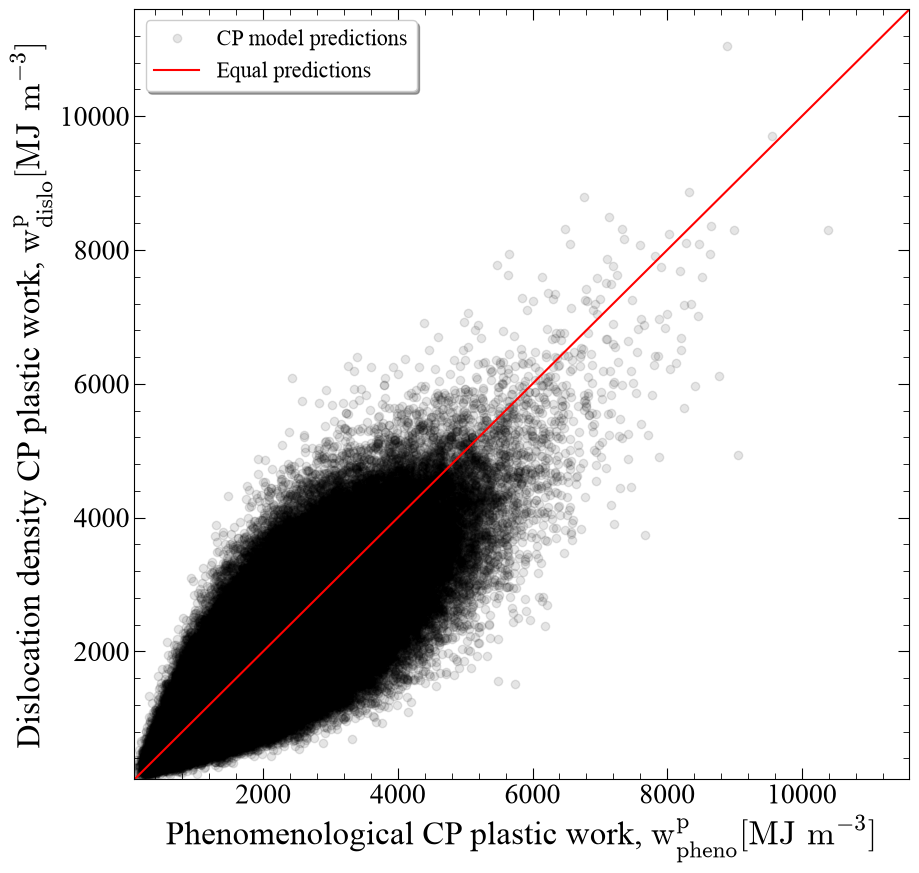

In [5]:
%matplotlib inline
CPanalysistools.comparison_plot(pheno_apsed.flatten(order = 'F')*1e-6, dislo_apsed.flatten(order = 'F')*1e-6, 
                                r"Phenomenological CP plastic work, $\text{w}^{\text{p}}_{\text{pheno}} [\text{MJ m}^{-3}]$",
                                r"Dislocation density CP plastic work, $\text{w}^{\text{p}}_{\text{dislo}} [\text{MJ m}^{-3}]$",
)                               #savefig = True,
                                #fig_name = "../figures/APSED_comparison_200_grains_128_VE.png")

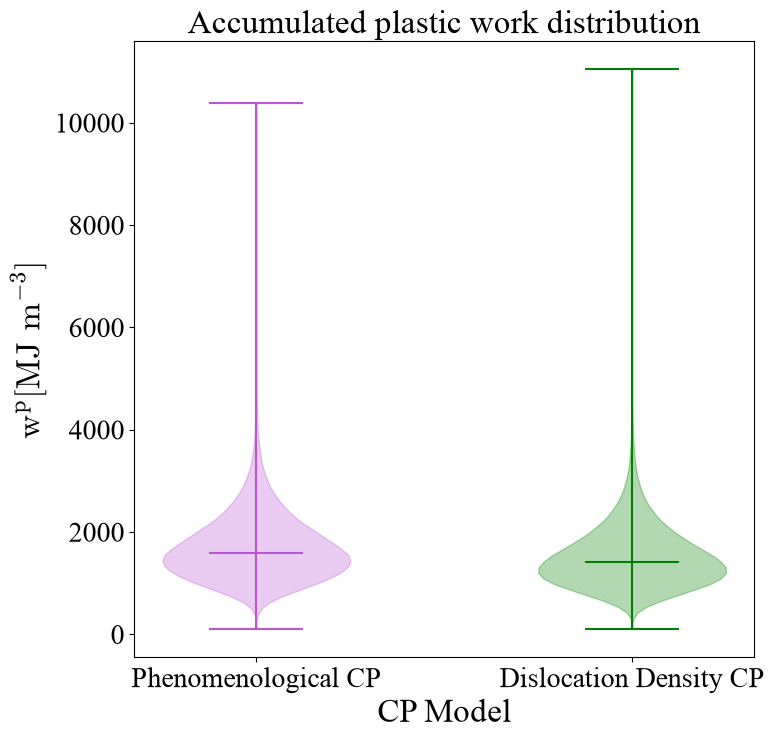

In [6]:
CPanalysistools.comparison_violin_plot(pheno_apsed.flatten(order = 'F')*1e-6, dislo_apsed.flatten(order = 'F')*1e-6, 
                       "Phenomenological CP", 
                       "Dislocation Density CP", 
                       "Accumulated plastic work distribution", 
                       r"$\text{w}^{\text{p}} [\text{MJ m}^{-3}]$",
                       savefig = True,
                       fig_name = "../figures/APSED_violin_plot_200_grains_128_VE.png")

Statistical comparison

In [7]:
CPanalysistools.statistical_comparison_metrics(pheno_apsed, dislo_apsed)

NRMSE (val 1 normalised): 0.242 
NRMSE (val 2 normalised): 0.271 
SSIM: 0.757 
Correlation coefficient: 0.832


Investigating maximum APSED

In [26]:
np.unravel_index(np.argmax(pheno_apsed.flatten(order = 'F')), pheno_apsed.shape, order = 'F'), np.unravel_index(np.argmax(dislo_apsed.flatten(order = 'F')), dislo_apsed.shape, order = 'F')

((np.int64(86), np.int64(9), np.int64(32)),
 (np.int64(110), np.int64(108), np.int64(77)))

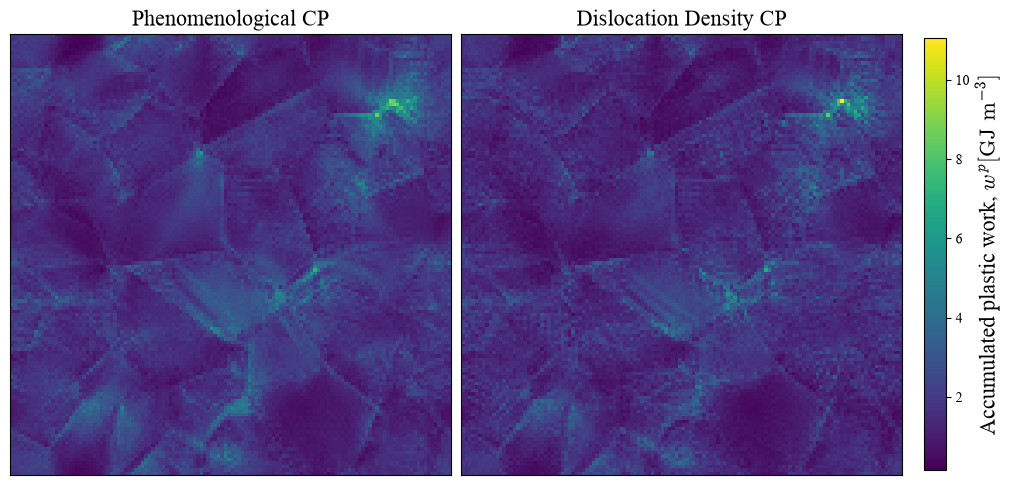

In [27]:
CPanalysistools.comparison_map(np.flip(pheno_apsed[:,:,77].transpose(), axis=0)*1e-9, 
                               np.flip(dislo_apsed[:,:,77].transpose(), axis=0)*1e-9,
                               data1_label = 'Phenomenological CP',
                               data2_label = 'Dislocation Density CP',
                               color_bar_label = r'Accumulated plastic work, $w^p [\text{GJ m}^{-3}]$')

PSED over different increments

In [62]:
pheno_psed_arrs.shape

(101, 128, 128, 128)

In [ ]:
# Extract SSIM for plastic work accumulated at each time step
psed_ssim_vals = []
for i in tqdm(range(len(pheno_psed_arrs))):
    max_val = max(max(pheno_psed_arrs[i].flatten(order='F')), max(dislo_psed_arrs[i].flatten(order='F')))
    min_val = min(min(pheno_psed_arrs[i].flatten(order='F')), min(dislo_psed_arrs[i].flatten(order='F')))
    psed_ssim = skimage.metrics.structural_similarity(pheno_psed_arrs[i], dislo_psed_arrs[i], data_range = max_val - min_val)
    psed_ssim_vals.append(psed_ssim)

  0%|          | 0/101 [00:00<?, ?it/s]/mnt/iusers01/jf01/j38714mw/matflow_v40a7-venv/lib/python3.13/site-packages/skimage/metrics/_structural_similarity.py:269: RuntimeWarning: invalid value encountered in divide
  S = (A1 * A2) / D
100%|██████████| 101/101 [02:20<00:00,  1.39s/it]


In [69]:
apsed_ssim_vals = []
i=0
pheno_apsed_inc = pheno_psed_arrs[0]
dislo_apsed_inc = dislo_psed_arrs[0]
while i < len(pheno_psed_arrs):
    if i > 0:
        pheno_apsed_inc = pheno_apsed_inc + pheno_psed_arrs[i]
        dislo_apsed_inc = dislo_apsed_inc + dislo_psed_arrs[i]

    max_val = max(max(pheno_apsed_inc.flatten(order='F')), max(dislo_apsed_inc.flatten(order='F')))
    min_val = min(min(pheno_apsed_inc.flatten(order='F')), min(dislo_apsed_inc.flatten(order='F')))
    apsed_ssim = skimage.metrics.structural_similarity(pheno_apsed_inc, dislo_apsed_inc, data_range = max_val - min_val)
    apsed_ssim_vals.append(apsed_ssim)
    pheno_apsed
    i+=1

/mnt/iusers01/jf01/j38714mw/matflow_v40a7-venv/lib/python3.13/site-packages/skimage/metrics/_structural_similarity.py:269: RuntimeWarning: invalid value encountered in divide
  S = (A1 * A2) / D


findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: 

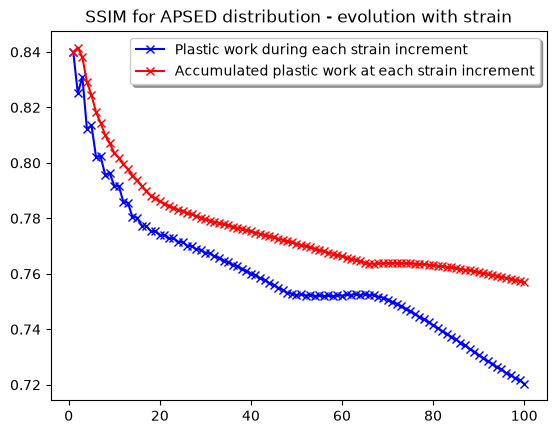

In [72]:
# This plots the similarity between the plastic work accumulated during each time step
plt.plot(np.linspace(0,100,101), psed_ssim_vals, color = 'blue', marker = "x", label = "Plastic work during each strain increment")
# This plots the accumulated plastic work at each time step
plt.plot(np.linspace(0,100,101), apsed_ssim_vals, color = 'red', marker = "x", label = "Accumulated plastic work at each strain increment")
plt.title("SSIM for APSED distribution - evolution with strain")
plt.legend(shadow = True)

### Maximum values per grain ID

In [44]:
material_IDs = np.load("../data/material_IDs_200_grains_128_cubed_VE.npy")

Stress triaxiality

In [ ]:
max_pheno_triax_from_grains = CPanalysistools.max_val_from_grains(pheno_triax, material_IDs, 200)
max_dislo_triax_from_grains = CPanalysistools.max_val_from_grains(dislo_triax, material_IDs, 200)

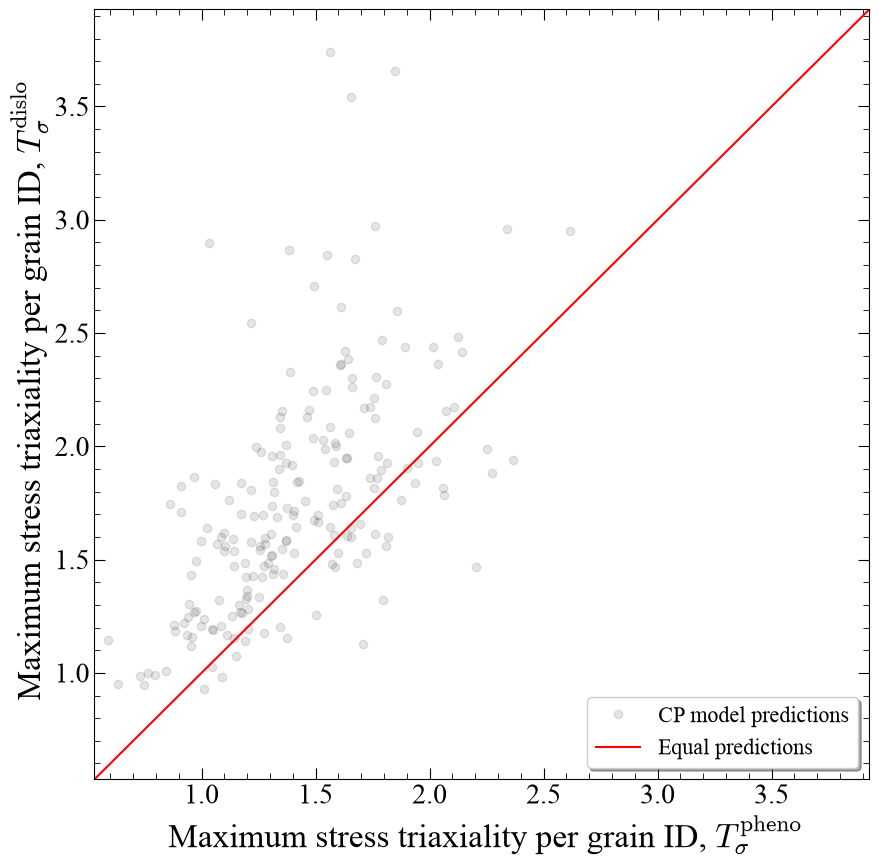

In [17]:
%matplotlib inline
CPanalysistools.comparison_plot(max_pheno_triax_from_grains, 
                                max_dislo_triax_from_grains, 
                                r" Maximum stress triaxiality per grain ID, $T_{\sigma}^{\text{pheno}}$", 
                                r" Maximum stress triaxiality per grain ID, $T_{\sigma}^{\text{dislo}}$")

$\varepsilon_{xx}$ strain

In [18]:
max_pheno_xx_strain_from_grains = CPanalysistools.max_val_from_grains(pheno_xx_strain, material_IDs, 200)
max_dislo_xx_strain_from_grains = CPanalysistools.max_val_from_grains(dislo_xx_strain, material_IDs, 200)

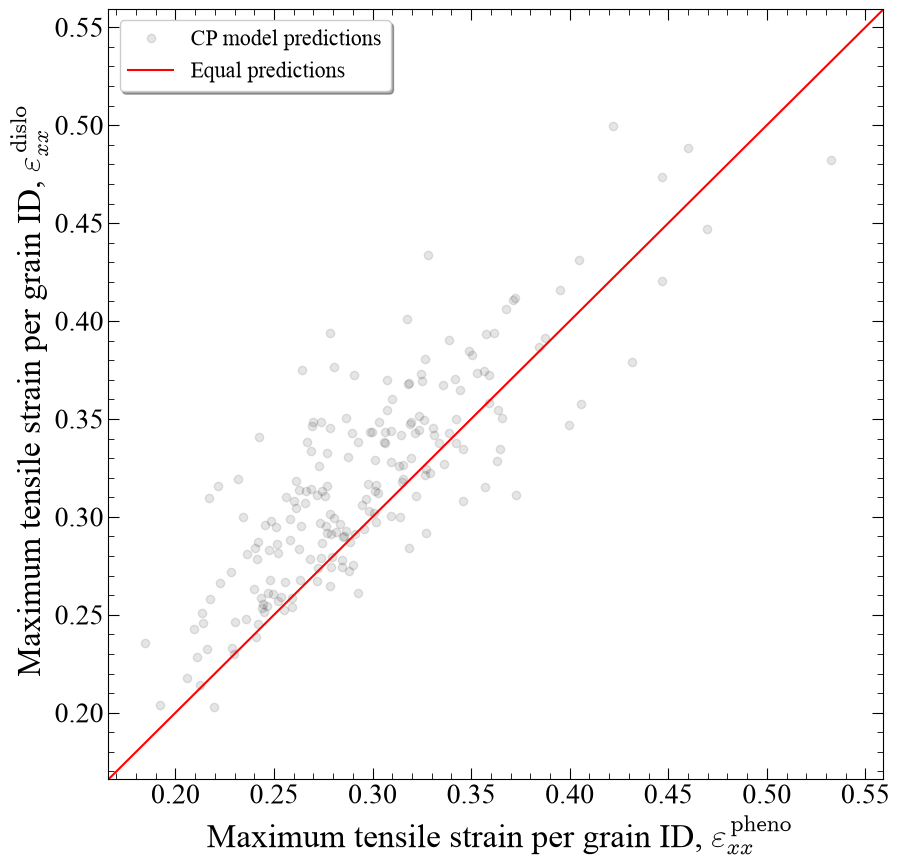

In [19]:
CPanalysistools.comparison_plot(max_pheno_xx_strain_from_grains, 
                                max_dislo_xx_strain_from_grains, 
                                r" Maximum tensile strain per grain ID, $\varepsilon_{xx}^{\text{pheno}}$", 
                                r" Maximum tensile strain per grain ID, $\varepsilon_{xx}^{\text{dislo}}$")

vM strain

In [20]:
max_pheno_vM_strain_from_grains = CPanalysistools.max_val_from_grains(pheno_vM_strain, material_IDs, 200)
max_dislo_vM_strain_from_grains = CPanalysistools.max_val_from_grains(dislo_vM_strain, material_IDs, 200)

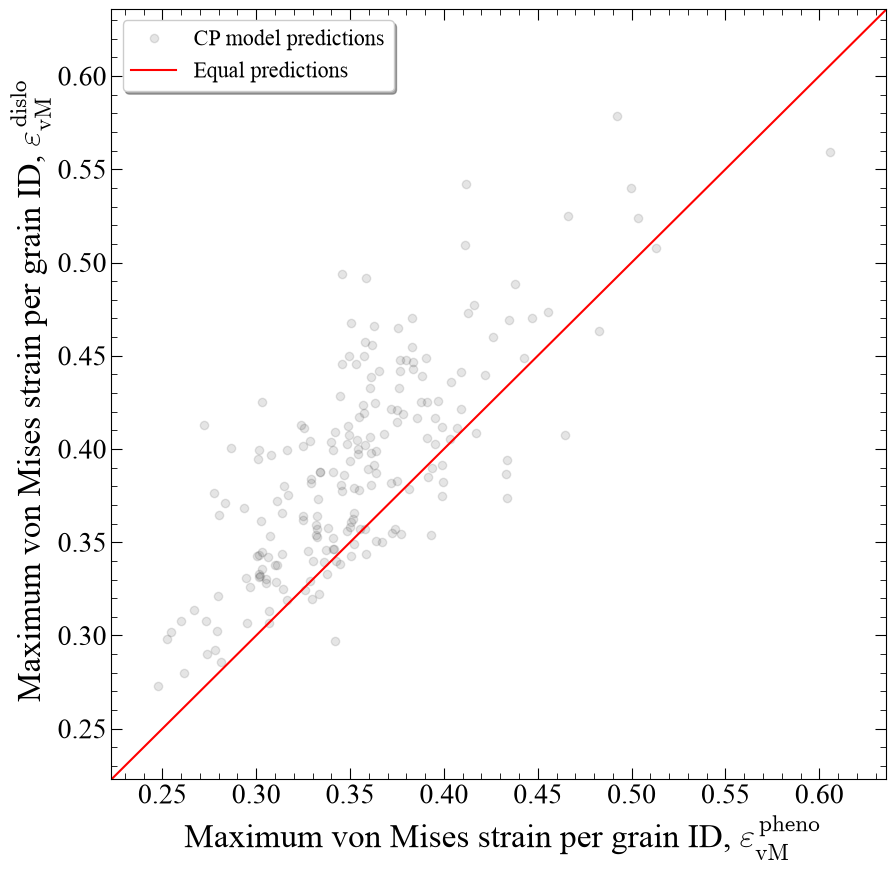

In [21]:
CPanalysistools.comparison_plot(max_pheno_vM_strain_from_grains, 
                                max_dislo_vM_strain_from_grains, 
                                r" Maximum von Mises strain per grain ID, $\varepsilon_{\text{vM}}^{\text{pheno}}$", 
                                r" Maximum von Mises strain per grain ID, $\varepsilon_{\text{vM}}^{\text{dislo}}$")

APSED

In [22]:
max_pheno_apsed_from_grains = CPanalysistools.max_val_from_grains(pheno_apsed, material_IDs, 200)
max_dislo_apsed_from_grains = CPanalysistools.max_val_from_grains(dislo_apsed, material_IDs, 200)

In [34]:
max_pheno_apsed_from_grains = np.array(max_pheno_apsed_from_grains)*1e-6
max_dislo_apsed_from_grains = np.array(max_dislo_apsed_from_grains)*1e-6

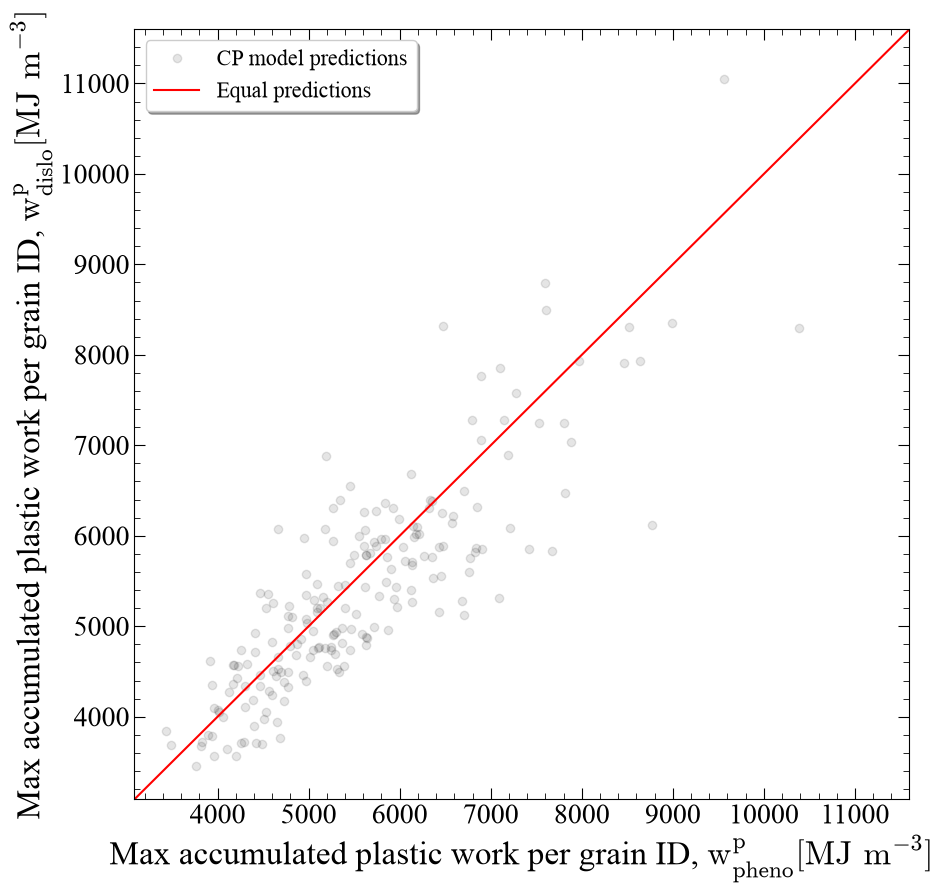

In [ ]:
CPanalysistools.comparison_plot(np.array(max_pheno_apsed_from_grains)*1e-6, 
                                np.array(max_dislo_apsed_from_grains)*1e-6, 
                                r"Max accumulated plastic work per grain ID, $\text{w}^{\text{p}}_{\text{pheno}} [\text{MJ m}^{-3}]$", 
                                r"Max accumulated plastic work per grain ID, $\text{w}^{\text{p}}_{\text{dislo}} [\text{MJ m}^{-3}]$",
                                savefig = True,
                                fig_name = "max_APSED_per_grain_200_grains_128_VE.png")

# Test stuff

In [8]:
def extract_slip_systems(material_file):
    mat = damask.ConfigMaterial.load(material_file)
    crystal_structure = damask.Crystal(lattice = mat['phase']['Cu']['lattice'])
    slip_dirs = crystal_structure.kinematics('slip')['direction'][0]
    slip_norms = crystal_structure.kinematics('slip')['plane'][0]

    return slip_dirs, slip_norms

In [9]:
def update_slip_systems(damask_view, slip_dirs, slip_norms, rve_shape):

    rot_matrices = damask.Rotation(damask_view.get('O')).reshape(rve_shape, order = 'F').as_matrix()

    #print(rot_matrices.shape)

    slip_dirs = np.broadcast_to(slip_dirs, [128,128,128,12,3])
    slip_norms = np.broadcast_to(slip_norms, [128,128,128,12,3])

    new_slip_dirs = np.einsum('...ij, ...ki -> ...kj', rot_matrices, slip_dirs)
    new_slip_norms = np.einsum('...ij, ...ki -> ...kj', rot_matrices, slip_norms)

    #print(new_slip_dirs.shape, new_slip_norms.shape)
    
    #all_new_slip_dirs = []
    #all_new_slip_norms = []


    #for i in range(len(rot_matrices)):
    #    new_slip_dirs = []
    #    new_slip_norms = []
    #    for j in range(len(slip_dirs)):
    #        new_slip_dir = rot_matrices[i] @ slip_dirs[j]
    #        new_slip_norm = rot_matrices[i] @ slip_norms[j]
    #        new_slip_dirs.append(new_slip_dir)
    #        new_slip_norms.append(new_slip_norm)
            
    #    all_new_slip_dirs.append(new_slip_dirs)
    #    all_new_slip_norms.append(new_slip_norms)

    return new_slip_dirs, new_slip_norms

In [13]:
def extract_accum_plastic_strain_energy_density(damask_file, mat_file, rve_shape):
    result = damask.Result(damask_file)

    slip_dirs, slip_norms = extract_slip_systems(mat_file)

    total_plastic_work_arrs = []

    for i in tqdm(range(len(result.increments))):
        x = result.view(increments = result.increments[i])
        gamma = x.get('gamma_sl').reshape([rve_shape[0], rve_shape[1], rve_shape[2], 12], order = 'F')
        #print(f"Gamma shape = {gamma.shape}")

        if i == 0:
            new_slip_dirs = np.broadcast_to(slip_dirs, [128,128,128,12,3])
            new_slip_norms = np.broadcast_to(slip_norms, [128,128,128,12,3])

        else:
            new_slip_dirs, new_slip_norms = update_slip_systems(x, slip_dirs, slip_norms, rve_shape)

        #print(f"New slip dirs shape = {new_slip_dirs.shape}, New slip norms shape = {new_slip_norms.shape}")

        sigma = x.get('sigma').reshape([rve_shape[0], rve_shape[1], rve_shape[2], 3, 3], order = 'F')

        #print(f"Sigma shape = {sigma.shape}")

        #print(new_slip_dirs.nbytes/(1024**3), new_slip_norms.nbytes/(1024**3))

        # Calculate resolved shear stresses
        #tau = np.einsum('vij,vsi,vsj->vs', sigma, new_slip_dirs, new_slip_norms)
        #slip_product = np.einsum('...ij, ...ik -> ...ijk', new_slip_dirs, new_slip_norms)

        #tau = np.tensordot(sigma, slip_product, axes = ([4,5], [3,4]))

        tau = np.einsum('...ij, ...si, ...sj -> ...s', sigma, new_slip_dirs, new_slip_norms)

        #print(f"Tau shape = {tau.shape}")

        plastic_work = np.abs(np.multiply(tau, gamma))

        #print(f"Plastic work shape = {plastic_work.shape}")

        total_plastic_work_per_inc = np.sum(plastic_work, axis=3)

        #print(f"Total plastic work per increment shape = {total_plastic_work_per_inc.shape}")

        if i == 0:
            total_plastic_work_arrs.append(total_plastic_work_per_inc)
        else:
            total_plastic_work_current_time_inc = total_plastic_work_per_inc - total_plastic_work_arrs[i-1]
            total_plastic_work_arrs.append(total_plastic_work_current_time_inc)

    total_plastic_work_arrs = np.array(total_plastic_work_arrs) # Should be shape [12,128,128,128]  

    accum_plastic_work = np.sum(total_plastic_work_arrs, axis = 0)

    return accum_plastic_work

In [42]:
pheno_slip_dirs, pheno_slip_norms = extract_slip_systems(pheno_mat_file)
pheno_result_test = damask.Result(pheno_file)
pheno_result_view = pheno_result_test.view(increments = 0)

In [33]:
new_pheno_slip_dirs, new_pheno_slip_norms = update_slip_systems(pheno_result_view, pheno_slip_dirs, pheno_slip_norms, [128,128,128])
new_pheno_slip_dirs, new_pheno_slip_norms

(128, 128, 128, 3, 3)
(128, 128, 128, 12, 3) (128, 128, 128, 12, 3)


(array([[[[[ 0.38819601, -0.92832702,  0.99373679],
           [ 0.86640986,  0.28161946, -1.08167667],
           [-1.25460588,  0.64670756,  0.08793988],
           ...,
           [ 1.18986796,  0.73222792,  0.21921797],
           [-0.86640986, -0.28161946,  1.08167667],
           [-0.32345809, -0.45060846, -1.30089464]],
 
          [[ 0.38819601, -0.92832702,  0.99373679],
           [ 0.86640986,  0.28161946, -1.08167667],
           [-1.25460588,  0.64670756,  0.08793988],
           ...,
           [ 1.18986796,  0.73222792,  0.21921797],
           [-0.86640986, -0.28161946,  1.08167667],
           [-0.32345809, -0.45060846, -1.30089464]],
 
          [[ 0.38819601, -0.92832702,  0.99373679],
           [ 0.86640986,  0.28161946, -1.08167667],
           [-1.25460588,  0.64670756,  0.08793988],
           ...,
           [ 1.18986796,  0.73222792,  0.21921797],
           [-0.86640986, -0.28161946,  1.08167667],
           [-0.32345809, -0.45060846, -1.30089464]],
 
       

In [15]:
pheno_apsed = extract_accum_plastic_strain_energy_density(pheno_file, pheno_mat_file, rve_shape=[128,128,128])

 45%|████▍     | 45/101 [02:23<03:11,  3.43s/it]

: 

In [ ]:
dislo_apsed = extract_accum_plastic_strain_energy_density(pheno_file, pheno_mat_file, rve_shape=[128,128,128])

Grain averaged stress triaxiality

In [41]:
dislo_mf_wk = mf.Workflow(dislo_wk)

In [112]:
dislo_task = dislo_mf_wk.tasks.generate_volume_element_from_voronoi.elements

VE = dislo_task.volume_element

VE

AttributeError: 'Elements' object has no attribute 'volume_element'

In [11]:
material_IDs = CPanalysistools.extract_material_IDs(pheno_wk)

/mnt/iusers01/jf01/j38714mw/matflow_v40a7-venv/lib/python3.13/site-packages/CPanalysistools/_CPanalysistools.py:420: SyntaxWarning: invalid escape sequence '\s'
  ax.set_ylabel('True stress, $\sigma_{xx}$ (MPa)', fontsize=label_fontsize)
/mnt/iusers01/jf01/j38714mw/matflow_v40a7-venv/lib/python3.13/site-packages/CPanalysistools/_CPanalysistools.py:421: SyntaxWarning: invalid escape sequence '\e'
  ax.set_xlabel('True strain, $\epsilon_{xx}$', fontsize=label_fontsize)


TypeError: 'NoneType' object is not subscriptable

In [ ]:
CPanalysistools.grain_averaged_values(pheno_triax, material_IDs, 200)